<a href="https://colab.research.google.com/github/juukonishi/Global-Solution-SERS/blob/main/analise_energia_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Citizen Assist AI – Módulo Energia
## Global Solution 2026.2 – Soluções em Energias Renováveis e Sustentáveis (SERS)

**Integrantes:**
- Júlia Konishi: 569506
- João Vitor Giadans: 571608
- João Victor Scheren: 568883

### 1. Contexto
- **Público:** famílias de baixa renda em residências da Grande São Paulo (4 pessoas, ligação bifásica, chuveiro elétrico).
- **Necessidade energética:** a conta de luz pesa no orçamento e o maior consumo é o **chuveiro elétrico**, principalmente no inverno.
- **Como o assistente ajuda:** o Citizen Assist AI explica quanto cada aparelho gasta, por que a conta sobe no inverno e compara alternativas de economia, incluindo **fontes renováveis** (aquecedor solar e energia fotovoltaica), sempre mostrando custos, limitações e fontes.

> Todos os dados marcados como **estimado** são estimativas justificadas, não medições. O período de referência é **1 mês** para consumo e **10 anos** para a comparação financeira.

## 0. Preparação no Google Colab
As células abaixo recriam os arquivos do projeto (`energia.py`, `assistente.py` e a pasta `dados/`) dentro do Colab

In [ ]:
!mkdir -p dados

In [ ]:
%%writefile energia.py
import json
import pandas as pd


def carregar_premissas_completas():
    with open("dados/premissas.json", encoding="utf-8") as arquivo:
        return json.load(arquivo)


def carregar_premissas():
    completas = carregar_premissas_completas()
    premissas = {}
    for nome in completas:
        premissas[nome] = completas[nome]["valor"]
    return premissas


def carregar_aparelhos():
    tabela = pd.read_csv("dados/aparelhos.csv")
    tabela["consumo_kwh_mes"] = tabela["potencia_w"] / 1000 * tabela["horas_dia"] * tabela["dias_mes"] * tabela["quantidade"]
    return tabela.to_dict("records")


def carregar_modelo():
    try:
        with open("dados/modelo_sazonalidade.json", encoding="utf-8") as arquivo:
            return json.load(arquivo)
    except FileNotFoundError:
        return None


def energia_kwh_mes(potencia_w, horas_dia, dias_mes, quantidade):
    return potencia_w / 1000 * horas_dia * dias_mes * quantidade


def consumo_chuveiro(potencia_w, pessoas, minutos):
    horas_dia = pessoas * minutos / 60
    return energia_kwh_mes(potencia_w, horas_dia, 30, 1)


def payback_meses(custo, economia_mensal):
    if economia_mensal <= 0:
        return float("inf")
    return custo / economia_mensal


class Perfil:
    def __init__(self, pessoas=4, minutos_banho=10, potencia_chuveiro_w=5500, ligacao="bifasico",
                 tarifa=None, consumo_conta_kwh=None, casa_propria=True, telhado_com_sol=True,
                 orcamento_r=0, aparelhos=None):
        self.pessoas = pessoas
        self.minutos_banho = minutos_banho
        self.potencia_chuveiro_w = potencia_chuveiro_w
        self.ligacao = ligacao
        self.tarifa = tarifa
        self.consumo_conta_kwh = consumo_conta_kwh
        self.casa_propria = casa_propria
        self.telhado_com_sol = telhado_com_sol
        self.orcamento_r = orcamento_r
        if aparelhos is None:
            aparelhos = carregar_aparelhos()
        self.aparelhos = aparelhos


def diagnostico(perfil, premissas):
    chuveiro = consumo_chuveiro(perfil.potencia_chuveiro_w, perfil.pessoas, perfil.minutos_banho)

    categorias = {}
    for aparelho in perfil.aparelhos:
        if aparelho["categoria"] != "chuveiro":
            categoria = aparelho["categoria"]
            categorias[categoria] = categorias.get(categoria, 0) + aparelho["consumo_kwh_mes"]
    categorias["chuveiro"] = chuveiro

    total = sum(categorias.values())
    if perfil.consumo_conta_kwh:
        total = perfil.consumo_conta_kwh
        chuveiro = min(chuveiro, 0.8 * total)
        categorias["chuveiro"] = chuveiro

    tarifa = premissas["tarifa_r_kwh"]
    if perfil.tarifa:
        tarifa = perfil.tarifa

    return {
        "consumo_total_kwh": total,
        "por_categoria_kwh": categorias,
        "chuveiro_kwh": chuveiro,
        "participacao_chuveiro": chuveiro / total,
        "tarifa": tarifa,
        "conta_estimada_r": total * tarifa,
    }


def montar(nome, renovavel, custo, economia_kwh, tarifa, premissas, viabilidade, impactos, limitacoes):
    economia_mes = economia_kwh * tarifa
    anos = premissas["horizonte_anos"]
    return {
        "alternativa": nome,
        "renovavel": renovavel,
        "custo_inicial_r": round(custo, 2),
        "economia_kwh_mes": round(economia_kwh, 1),
        "economia_r_mes": round(economia_mes, 2),
        "economia_r_ano": round(economia_mes * 12, 2),
        "payback_meses": round(payback_meses(custo, economia_mes), 1),
        f"saldo_{anos}_anos_r": round(economia_mes * 12 * anos - custo, 2),
        "co2_evitado_kg_ano": round(economia_kwh * 12 * premissas["fator_emissao_sin"], 1),
        "viabilidade": viabilidade,
        "impactos_ambientais": impactos,
        "limitacoes": limitacoes,
    }


def alternativa_eficiencia(perfil, premissas):
    diagnostico_casa = diagnostico(perfil, premissas)

    minutos_meta = min(perfil.minutos_banho, premissas["minutos_banho_meta"])
    chuveiro_novo = consumo_chuveiro(perfil.potencia_chuveiro_w, perfil.pessoas, minutos_meta)
    economia_banho = diagnostico_casa["chuveiro_kwh"] - chuveiro_novo

    economia_led = 0
    lampadas = 0
    standby = 0
    for aparelho in perfil.aparelhos:
        if aparelho["categoria"] == "iluminacao" and aparelho["potencia_w"] > premissas["potencia_led_w"]:
            diferenca = aparelho["potencia_w"] - premissas["potencia_led_w"]
            economia_led += energia_kwh_mes(diferenca, aparelho["horas_dia"], aparelho["dias_mes"], aparelho["quantidade"])
            lampadas += aparelho["quantidade"]
        if aparelho["categoria"] == "standby":
            standby += aparelho["consumo_kwh_mes"]
    economia_standby = standby * premissas["fracao_standby_evitavel"]

    custo = lampadas * premissas["preco_led_r"]
    if standby > 0:
        custo += premissas["preco_regua_r"]

    resultado = montar(
        "A) Eficiência e uso consciente", False, custo,
        economia_banho + economia_led + economia_standby, diagnostico_casa["tarifa"], premissas,
        "Alta: baixo custo, serve para casa alugada, não precisa de obra.",
        "Reduz consumo de energia e, no caso do banho, também de água. Lâmpadas antigas devem ir para pontos de coleta (fluorescentes têm mercúrio).",
        [
            "Depende da mudança de hábito da família; a economia some se o hábito voltar.",
            f"Considera banho de {perfil.minutos_banho:g} min reduzido para {minutos_meta:g} min.",
        ],
    )
    resultado["detalhe_kwh_mes"] = {
        "banho": round(economia_banho, 1),
        "led": round(economia_led, 1),
        "standby": round(economia_standby, 1),
    }
    return resultado


def alternativa_aquecedor_solar(perfil, premissas):
    diagnostico_casa = diagnostico(perfil, premissas)
    economia = diagnostico_casa["chuveiro_kwh"] * premissas["fracao_solar_aquecedor"]

    pessoas_extras = 0
    if perfil.pessoas > 4:
        pessoas_extras = perfil.pessoas - 4
    custo = premissas["custo_aquecedor_solar_r"] + pessoas_extras * premissas["custo_aquecedor_por_pessoa_extra_r"]

    return montar(
        "B) Aquecedor solar de água", True, custo, economia, diagnostico_casa["tarifa"], premissas,
        "Média: exige telhado com sol (face norte), estrutura para o reservatório e instalação hidráulica. Mais indicado para casa própria.",
        "Fonte renovável; reduz a demanda no horário de pico (18h-21h), quando o chuveiro pesa na rede. Fabricação usa cobre, alumínio e vidro; vida útil típica de 15-20 anos.",
        [
            f"Fração solar assumida de {premissas['fracao_solar_aquecedor']:.0%}; em dias nublados e no inverno o chuveiro elétrico complementa.",
            "Custo de instalação varia muito conforme o telhado e a hidráulica da casa.",
        ],
    )


def alternativa_fotovoltaica(perfil, premissas):
    diagnostico_casa = diagnostico(perfil, premissas)
    minimo = premissas["minimo_" + perfil.ligacao + "_kwh"]

    energia_alvo = max(diagnostico_casa["consumo_total_kwh"] - minimo, 0)
    geracao_por_kwp = premissas["hsp_sao_paulo"] * 30 * premissas["performance_ratio_fv"]

    kwp = 0
    custo = 0
    if energia_alvo > 0:
        kwp = energia_alvo / geracao_por_kwp
        custo = max(kwp * 1000 * premissas["custo_fv_r_por_wp"], premissas["custo_fv_minimo_r"])

    economia = energia_alvo * (1 - premissas["fator_fio_b"])

    resultado = montar(
        "C) Energia solar fotovoltaica", True, custo, economia, diagnostico_casa["tarifa"], premissas,
        "Baixa a média para o público: exige casa própria, telhado com sol e capital inicial ou financiamento.",
        "Fonte renovável sem emissão na operação. Fabricação dos módulos tem pegada de carbono e os painéis precisam de descarte/reciclagem adequado ao fim da vida útil (~25 anos).",
        [
            f"Continua pagando o mínimo de {minimo} kWh ({perfil.ligacao}) e a iluminação pública.",
            "Geração varia com o clima e a estação; HSP é uma média anual.",
            "A cobrança do Fio B (Lei 14.300/2022) foi simplificada como um desconto fixo.",
        ],
    )
    resultado["potencia_kwp"] = round(kwp, 2)
    resultado["geracao_kwh_mes"] = round(kwp * geracao_por_kwp, 1)
    resultado["area_telhado_m2"] = round(kwp * premissas["area_fv_m2_por_kwp"], 1)
    resultado["co2_evitado_kg_ano"] = round(energia_alvo * 12 * premissas["fator_emissao_sin"], 1)
    return resultado


def comparar_alternativas(perfil, premissas):
    eficiencia = alternativa_eficiencia(perfil, premissas)
    aquecedor = alternativa_aquecedor_solar(perfil, premissas)
    fotovoltaica = alternativa_fotovoltaica(perfil, premissas)
    return [eficiencia, aquecedor, fotovoltaica]


def recomendar(perfil, premissas):
    eficiencia, aquecedor, fotovoltaica = comparar_alternativas(perfil, premissas)
    motivos = []
    motivos.append(
        f"1º passo: {eficiencia['alternativa']} - custa cerca de R$ {eficiencia['custo_inicial_r']:.0f} e "
        f"economiza ~R$ {eficiencia['economia_r_mes']:.0f}/mês (paga-se em ~{eficiencia['payback_meses']:.0f} meses)."
    )

    if not (perfil.casa_propria and perfil.telhado_com_sol):
        motivos.append(
            "Como a casa não é própria ou o telhado não recebe sol, as opções solares ficam inviáveis por enquanto. "
            "Uma alternativa é procurar a geração compartilhada (assinatura de energia solar), que não exige obra."
        )
        return {"motivos": motivos}

    if aquecedor["payback_meses"] <= fotovoltaica["payback_meses"]:
        melhor = aquecedor
        outra = fotovoltaica
    else:
        melhor = fotovoltaica
        outra = aquecedor

    escolhida = None
    if melhor["custo_inicial_r"] <= perfil.orcamento_r:
        escolhida = melhor
    elif outra["custo_inicial_r"] <= perfil.orcamento_r:
        escolhida = outra

    if escolhida is not None:
        motivos.append(
            f"2º passo: {escolhida['alternativa']} - cabe no orçamento informado (R$ {perfil.orcamento_r:.0f}), "
            f"custa ~R$ {escolhida['custo_inicial_r']:.0f} e retorna em ~{escolhida['payback_meses'] / 12:.1f} anos."
        )
    else:
        if aquecedor["custo_inicial_r"] <= fotovoltaica["custo_inicial_r"]:
            mais_barata = aquecedor
        else:
            mais_barata = fotovoltaica
        motivos.append(
            f"Para uma fonte renovável, a opção de menor custo é {mais_barata['alternativa']} "
            f"(~R$ {mais_barata['custo_inicial_r']:.0f}). Vale juntar a economia do 1º passo ou buscar programas "
            "de habitação/financiamento antes de investir."
        )

    if diagnostico(perfil, premissas)["participacao_chuveiro"] >= 0.35:
        motivos.append("O chuveiro é a maior parte da sua conta, por isso o aquecedor solar costuma dar mais retorno por real investido.")
    return {"motivos": motivos}


Overwriting energia.py


In [ ]:
%%writefile assistente.py
import pandas as pd

from energia import (
    Perfil,
    carregar_modelo,
    carregar_premissas,
    carregar_premissas_completas,
    comparar_alternativas,
    diagnostico,
    recomendar,
)

AVISO = ("Atenção: os valores são ESTIMATIVAS com base nas premissas do projeto, "
         "não são garantia de economia. Confira sempre a sua conta de luz.")

REFERENCIAS = [
    "ANEEL - Resolução Normativa nº 1.000/2021 (custo de disponibilidade).",
    "ANEEL - Ranking das tarifas residenciais: portalrelatorios.aneel.gov.br/luznatarifa",
    "Lei nº 14.300/2022 - Marco legal da micro e minigeração distribuída.",
    "Lei nº 12.212/2010 - Tarifa Social de Energia Elétrica.",
    "CRESESB/CEPEL - SunData v3 (irradiação solar): cresesb.cepel.br",
    "CRESESB/CEPEL - Manual de Engenharia para Sistemas Fotovoltaicos (2014).",
    "MCTI - Fatores de emissão de CO2 do Sistema Interligado Nacional.",
    "INMETRO - Programa Brasileiro de Etiquetagem (tabelas de chuveiros, refrigeradores e lâmpadas).",
    "PROCEL - Dicas de economia de energia: procelinfo.com.br",
    "INMET - Normais Climatológicas 1991-2020 (temperatura média de São Paulo).",
]

AJUDA = ("Posso ajudar com: 'quanto gasta meu chuveiro', 'vale a pena energia solar', 'lâmpada LED', "
         "'standby', 'por que a conta sobe no inverno', 'tarifa social', 'como economizar na conta', "
         "'comparar alternativas', 'referências', 'limitações'.")


def sem_acento(texto):
    texto = texto.lower()
    com = "áàâãéêíóôõúç"
    sem = "aaaaeeiooouc"
    for i in range(len(com)):
        texto = texto.replace(com[i], sem[i])
    return texto


def reais(valor):
    texto = f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return "R$ " + texto


def resposta_chuveiro(perfil, premissas):
    diagnostico_casa = diagnostico(perfil, premissas)
    eficiencia = comparar_alternativas(perfil, premissas)[0]
    horas = perfil.pessoas * perfil.minutos_banho / 60
    return (
        f"O chuveiro de {perfil.potencia_chuveiro_w:.0f} W, com {perfil.pessoas} banhos de "
        f"{perfil.minutos_banho:g} min por dia, gasta cerca de {diagnostico_casa['chuveiro_kwh']:.0f} kWh/mês "
        f"(~{diagnostico_casa['participacao_chuveiro']:.0%} da conta, ~{reais(diagnostico_casa['chuveiro_kwh'] * diagnostico_casa['tarifa'])}/mês).\n"
        f"Conta: {perfil.potencia_chuveiro_w / 1000:.1f} kW x {horas:.2f} h/dia x 30 dias.\n"
        f"Dica: reduzir o banho para {premissas['minutos_banho_meta']:g} min economiza ~{eficiencia['detalhe_kwh_mes']['banho']:.0f} kWh/mês. "
        "Usar a posição 'verão' (morno) também reduz a potência."
    )


def resposta_solar(perfil, premissas):
    eficiencia, aquecedor, fotovoltaica = comparar_alternativas(perfil, premissas)
    return (
        "Existem dois tipos de energia solar para casa:\n"
        f"- Aquecedor solar de água: ~{reais(aquecedor['custo_inicial_r'])}, economia de ~{reais(aquecedor['economia_r_mes'])}/mês, "
        f"retorno em ~{aquecedor['payback_meses'] / 12:.1f} anos.\n"
        f"- Painéis fotovoltaicos: sistema de ~{fotovoltaica['potencia_kwp']} kWp (~{fotovoltaica['area_telhado_m2']} m² de telhado), "
        f"~{reais(fotovoltaica['custo_inicial_r'])}, economia de ~{reais(fotovoltaica['economia_r_mes'])}/mês, retorno em ~{fotovoltaica['payback_meses'] / 12:.1f} anos.\n"
        "Os dois precisam de telhado com sol e, em geral, casa própria. "
        f"Limitação: {fotovoltaica['limitacoes'][0]}"
    )


def resposta_led(perfil, premissas):
    eficiencia = comparar_alternativas(perfil, premissas)[0]
    return (
        f"Trocar as lâmpadas por LED de {premissas['potencia_led_w']:g} W economiza ~{eficiencia['detalhe_kwh_mes']['led']:.1f} kWh/mês. "
        "É pouco perto do chuveiro, mas o custo é baixo e a lâmpada LED dura mais. "
        "Descarte as fluorescentes em pontos de coleta (contêm mercúrio)."
    )


def resposta_standby(perfil, premissas):
    eficiencia = comparar_alternativas(perfil, premissas)[0]
    return (
        f"Aparelhos em espera (standby) ficam ligados 24 h. Na casa-modelo isso dá ~{eficiencia['detalhe_kwh_mes']['standby']:.1f} kWh/mês "
        "que podem ser evitados desligando TV e receptor na régua com interruptor."
    )


def resposta_inverno(perfil, premissas):
    modelo = carregar_modelo()
    if modelo is None:
        return "Rode o notebook de análise para gerar o modelo de sazonalidade."
    kwh_por_grau = -modelo["coeficiente_kwh_por_c"]
    return (
        "No inverno a água chega mais fria e o banho fica mais longo e mais quente, por isso o chuveiro gasta mais.\n"
        f"Pela regressão linear do histórico de exemplo, cada 1 °C a menos na temperatura média do mês "
        f"aumenta o consumo em ~{kwh_por_grau:.1f} kWh (R² = {modelo['r2']:.2f}).\n"
        f"Ex.: de janeiro (~23 °C) para julho (~17 °C) a conta sobe ~{kwh_por_grau * 6:.0f} kWh "
        f"(~{reais(kwh_por_grau * 6 * premissas['tarifa_r_kwh'])}).\n"
        "Limitação: o modelo usa dados de exemplo de 12 meses; use o histórico da sua conta para um resultado real."
    )


def resposta_tarifa_social(perfil, premissas):
    return (
        "A Tarifa Social de Energia Elétrica (Lei 12.212/2010) dá desconto na conta para famílias inscritas no "
        "CadÚnico com renda até meio salário mínimo por pessoa ou que recebem BPC. "
        "Procure o CRAS da sua região ou a distribuidora. Os cálculos deste assistente usam a tarifa cheia, "
        "então com o desconto o valor em reais da economia é menor."
    )


def resposta_comparar(perfil, premissas):
    anos = premissas["horizonte_anos"]
    texto = "Comparação para o mesmo período (valores estimados):\n\n"
    for alternativa in comparar_alternativas(perfil, premissas):
        renovavel = ""
        if alternativa["renovavel"]:
            renovavel = " (renovável)"
        texto += (
            f"{alternativa['alternativa']}{renovavel}\n"
            f" custo inicial {reais(alternativa['custo_inicial_r'])} | economia {alternativa['economia_kwh_mes']:.0f} kWh/mês "
            f"= {reais(alternativa['economia_r_mes'])}/mês | payback {alternativa['payback_meses']:.0f} meses | "
            f"saldo em {anos} anos {reais(alternativa[f'saldo_{anos}_anos_r'])} | CO2 evitado {alternativa['co2_evitado_kg_ano']:.0f} kg/ano\n"
            f" viabilidade: {alternativa['viabilidade']}\n"
        )
    texto += "\nRecomendação:\n"
    for motivo in recomendar(perfil, premissas)["motivos"]:
        texto += "- " + motivo + "\n"
    return texto.strip()


def resposta_conta(perfil, premissas):
    diagnostico_casa = diagnostico(perfil, premissas)
    categorias = pd.Series(diagnostico_casa["por_categoria_kwh"]).sort_values(ascending=False).head(3)
    lista = ""
    for nome in categorias.index:
        lista += f"{nome} ({categorias[nome]:.0f} kWh), "
    lista = lista[:-2]
    return (
        f"Consumo estimado: {diagnostico_casa['consumo_total_kwh']:.0f} kWh/mês (~{reais(diagnostico_casa['conta_estimada_r'])} sem iluminação pública e bandeiras).\n"
        f"Maiores gastos: {lista}.\n\n" + resposta_comparar(perfil, premissas)
    )


def resposta_limitacoes(perfil, premissas):
    completas = carregar_premissas_completas()
    linhas = ""
    for nome in completas:
        info = completas[nome]
        if info["tipo"] == "estimado":
            linhas += f"- {info['descricao']}: {info['valor']} {info['unidade']}\n"
    return (
        "Limitações das estimativas:\n"
        "- Os resultados dependem das premissas abaixo (marcadas como estimadas) e dos hábitos da família.\n"
        "- Não consideram inflação, juros, reajuste de tarifa, bandeiras tarifárias nem degradação dos painéis.\n"
        "- O payback é simples; investimentos devem ser confirmados com orçamentos reais e profissional habilitado.\n"
        "Premissas estimadas:\n" + linhas.strip()
    )


def resposta_referencias():
    texto = "Referências utilizadas:\n"
    for referencia in REFERENCIAS:
        texto += "- " + referencia + "\n"
    return texto.strip()


def responder(pergunta, perfil=None, premissas=None):
    if perfil is None:
        perfil = Perfil()
    if premissas is None:
        premissas = carregar_premissas()
    texto = sem_acento(pergunta)

    if "referencia" in texto or "fontes usadas" in texto or "de onde vem" in texto:
        return resposta_referencias()
    elif "limitac" in texto or "garant" in texto or "premissa" in texto:
        resposta = resposta_limitacoes(perfil, premissas)
    elif "tarifa social" in texto or "desconto" in texto or "cadunico" in texto or "baixa renda" in texto:
        resposta = resposta_tarifa_social(perfil, premissas)
    elif "inverno" in texto or "frio" in texto or "sobe" in texto or "subiu" in texto or "aumentou" in texto:
        resposta = resposta_inverno(perfil, premissas)
    elif "chuveiro" in texto or "banho" in texto:
        resposta = resposta_chuveiro(perfil, premissas)
    elif "aquecedor" in texto or "solar" in texto or "painel" in texto or "placa" in texto or "fotovolt" in texto or "renovav" in texto:
        resposta = resposta_solar(perfil, premissas)
    elif "led" in texto or "lampada" in texto or "iluminacao" in texto:
        resposta = resposta_led(perfil, premissas)
    elif "standby" in texto or "tomada" in texto or "espera" in texto:
        resposta = resposta_standby(perfil, premissas)
    elif "compar" in texto or "alternativa" in texto or "opcoes" in texto:
        resposta = resposta_comparar(perfil, premissas)
    elif "conta" in texto or "economiz" in texto or "gasto" in texto or "consumo" in texto or "reduzir" in texto:
        resposta = resposta_conta(perfil, premissas)
    else:
        return AJUDA

    return resposta + f"\n\n{AVISO}\nDigite 'referências' para ver as fontes."


def main():
    print("Citizen Assist AI - Módulo Energia (SERS)")
    print(AJUDA)
    perfil = Perfil()
    while True:
        pergunta = input("\nVocê: ")
        if sem_acento(pergunta) in ["sair", "tchau", "exit"]:
            break
        print("Assistente: " + responder(pergunta, perfil))
    print("Até mais! Economizar energia também é cuidar do planeta.")


if __name__ == "__main__":
    main()


Overwriting assistente.py


In [ ]:
%%writefile dados/aparelhos.csv
aparelho,potencia_w,quantidade,horas_dia,dias_mes,categoria,tipo_dado,fonte
Chuveiro elétrico,5500,1,0.667,30,chuveiro,estimado,"Potência típica (INMETRO PBE chuveiros); 4 banhos de 10 min por dia"
Geladeira 1 porta,40,1,24,30,refrigeracao,estimado,"Potência média equivalente a ~29 kWh/mês (etiqueta PROCEL A, INMETRO PBE)"
Lâmpada fluorescente compacta,15,6,5,30,iluminacao,estimado,"6 pontos de luz acesos 5 h/dia"
Televisor LED 40 pol,90,1,5,30,entretenimento,estimado,"Potência de etiqueta típica"
Ventilador,100,1,4,30,climatizacao,estimado,"Média anual (mais uso no verão)"
Micro-ondas,1200,1,0.25,30,cozinha,estimado,"15 min/dia"
Máquina de lavar,500,1,1,12,lavanderia,estimado,"3 lavagens por semana"
Ferro de passar,1000,1,1,4,lavanderia,estimado,"1 h por semana"
Carregadores de celular,5,3,3,30,eletronicos,estimado,"3 aparelhos"
Standby (TV / receptor / micro-ondas),10,1,24,30,standby,estimado,"Soma estimada de aparelhos em espera"


Overwriting dados/aparelhos.csv


In [ ]:
%%writefile dados/historico_exemplo.csv
mes,temp_media_c,consumo_kwh
jan,22.9,188
fev,23.2,176
mar,22.5,190
abr,20.9,192
mai,18.4,218
jun,17.3,214
jul,16.6,231
ago,17.9,212
set,18.8,214
out,20.3,196
nov,21.2,197
dez,22.2,181


Overwriting dados/historico_exemplo.csv


In [ ]:
%%writefile dados/modelo_sazonalidade.json
{
  "coeficiente_kwh_por_c": -6.89,
  "intercepto_kwh": 339.81,
  "r2": 0.907,
  "mae_kwh": 4.78,
  "dados": "historico_exemplo.csv (fictício) + INMET normais 1991-2020"
}


Overwriting dados/modelo_sazonalidade.json


In [ ]:
%%writefile dados/premissas.json
{
  "tarifa_r_kwh": {
    "valor": 0.80,
    "unidade": "R$/kWh",
    "tipo": "estimado",
    "descricao": "Tarifa residencial B1 com tributos (ICMS, PIS/COFINS) e sem bandeira, valor aproximado para a Grande São Paulo",
    "fonte": "ANEEL - Ranking das tarifas residenciais (portalrelatorios.aneel.gov.br/luznatarifa). Arredondado; conferir na conta de luz do usuário"
  },
  "minimo_monofasico_kwh": {
    "valor": 30,
    "unidade": "kWh/mês",
    "tipo": "público",
    "descricao": "Custo de disponibilidade, ligação monofásica",
    "fonte": "ANEEL - Resolução Normativa nº 1.000/2021"
  },
  "minimo_bifasico_kwh": {
    "valor": 50,
    "unidade": "kWh/mês",
    "tipo": "público",
    "descricao": "Custo de disponibilidade, ligação bifásica",
    "fonte": "ANEEL - Resolução Normativa nº 1.000/2021"
  },
  "minimo_trifasico_kwh": {
    "valor": 100,
    "unidade": "kWh/mês",
    "tipo": "público",
    "descricao": "Custo de disponibilidade, ligação trifásica",
    "fonte": "ANEEL - Resolução Normativa nº 1.000/2021"
  },
  "hsp_sao_paulo": {
    "valor": 4.5,
    "unidade": "kWh/m²/dia (horas de sol pleno)",
    "tipo": "público (aproximado)",
    "descricao": "Irradiação média anual no plano inclinado para São Paulo-SP",
    "fonte": "CRESESB/CEPEL - SunData v3 (cresesb.cepel.br). Valor arredondado"
  },
  "performance_ratio_fv": {
    "valor": 0.75,
    "unidade": "adimensional",
    "tipo": "estimado",
    "descricao": "Taxa de desempenho do sistema fotovoltaico (perdas por temperatura, sujeira, cabos e inversor)",
    "fonte": "Faixa típica 0,70-0,80 citada no Manual de Engenharia para Sistemas Fotovoltaicos (CRESESB/CEPEL, 2014)"
  },
  "custo_fv_r_por_wp": {
    "valor": 4.00,
    "unidade": "R$/Wp",
    "tipo": "estimado",
    "descricao": "Preço instalado de sistema residencial pequeno (até ~3 kWp)",
    "fonte": "Estimativa baseada nos estudos de mercado de GD da Greener (2024-2025). Pedir orçamentos reais"
  },
  "custo_fv_minimo_r": {
    "valor": 5000,
    "unidade": "R$",
    "tipo": "estimado",
    "descricao": "Custo mínimo de um projeto FV (projeto, homologação, mão de obra), mesmo para sistemas muito pequenos",
    "fonte": "Estimativa do grupo"
  },
  "area_fv_m2_por_kwp": {
    "valor": 5.0,
    "unidade": "m²/kWp",
    "tipo": "estimado",
    "descricao": "Área de telhado ocupada por kWp com módulos de ~20% de eficiência",
    "fonte": "Folhas de dados de módulos comerciais (~2 m² por módulo de 400-550 Wp)"
  },
  "fator_fio_b": {
    "valor": 0.15,
    "unidade": "fração da tarifa",
    "tipo": "estimado",
    "descricao": "Parcela da tarifa que deixa de ser compensada pela cobrança gradual do Fio B na energia injetada",
    "fonte": "Lei nº 14.300/2022 (regra de transição). Simplificação do grupo"
  },
  "potencia_led_w": {
    "valor": 9,
    "unidade": "W",
    "tipo": "público",
    "descricao": "Lâmpada LED bulbo equivalente a 60 W incandescente / 15 W fluorescente",
    "fonte": "INMETRO - Tabelas PBE de lâmpadas LED"
  },
  "preco_led_r": {
    "valor": 12,
    "unidade": "R$/unidade",
    "tipo": "estimado",
    "descricao": "Preço de varejo de uma lâmpada LED 9 W",
    "fonte": "Pesquisa de preço em varejo (estimativa)"
  },
  "preco_regua_r": {
    "valor": 40,
    "unidade": "R$",
    "tipo": "estimado",
    "descricao": "Filtro de linha com interruptor para cortar o standby",
    "fonte": "Pesquisa de preço em varejo (estimativa)"
  },
  "fracao_standby_evitavel": {
    "valor": 0.7,
    "unidade": "fração",
    "tipo": "estimado",
    "descricao": "Parte do consumo em standby que pode ser eliminada desligando aparelhos na régua",
    "fonte": "Estimativa do grupo"
  },
  "minutos_banho_meta": {
    "valor": 7,
    "unidade": "min",
    "tipo": "estimado",
    "descricao": "Meta de duração do banho usada na alternativa de eficiência",
    "fonte": "Recomendação de uso consciente (PROCEL - dicas de economia)"
  },
  "fracao_solar_aquecedor": {
    "valor": 0.6,
    "unidade": "fração",
    "tipo": "estimado",
    "descricao": "Fração do aquecimento de água do banho atendida pelo aquecedor solar ao longo do ano (o chuveiro elétrico continua como apoio)",
    "fonte": "Faixa 60-80% citada por programas de aquecimento solar em habitação social; adotado o valor conservador"
  },
  "custo_aquecedor_solar_r": {
    "valor": 3000,
    "unidade": "R$",
    "tipo": "estimado",
    "descricao": "Aquecedor solar de 200 L (até 4 pessoas), instalado",
    "fonte": "Estimativa de mercado; pedir orçamentos reais"
  },
  "custo_aquecedor_por_pessoa_extra_r": {
    "valor": 600,
    "unidade": "R$/pessoa",
    "tipo": "estimado",
    "descricao": "Acréscimo de reservatório/coletor por pessoa acima de 4",
    "fonte": "Estimativa do grupo"
  },
  "fator_emissao_sin": {
    "valor": 0.0385,
    "unidade": "kg CO2/kWh (= tCO2/MWh)",
    "tipo": "público",
    "descricao": "Fator médio anual de emissão do Sistema Interligado Nacional (2023)",
    "fonte": "MCTI - Fatores de emissão de CO2 do SIN. Conferir o ano mais recente"
  },
  "horizonte_anos": {
    "valor": 10,
    "unidade": "anos",
    "tipo": "premissa",
    "descricao": "Período de referência comum para comparar as alternativas",
    "fonte": "Escolha do grupo"
  }
}


Overwriting dados/premissas.json


## 2. Importação das bibliotecas

In [ ]:
import json

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import energia as en

pd.set_option('display.max_colwidth', 80)

## 3. Premissas e origem dos dados
Cada premissa tem unidade, tipo (público / estimado) e fonte.

In [ ]:
premissas_df = pd.DataFrame(en.carregar_premissas_completas()).T[['valor', 'unidade', 'tipo', 'fonte']]
premissas_df

,valor,unidade,tipo,fonte
tarifa_r_kwh,0.8,R$/kWh,estimado,ANEEL - Ranking das tarifas residenciais (portalrelatorios.aneel.gov.br/luzn...
minimo_monofasico_kwh,30,kWh/mês,público,ANEEL - Resolução Normativa nº 1.000/2021
minimo_bifasico_kwh,50,kWh/mês,público,ANEEL - Resolução Normativa nº 1.000/2021
minimo_trifasico_kwh,100,kWh/mês,público,ANEEL - Resolução Normativa nº 1.000/2021
hsp_sao_paulo,4.5,kWh/m²/dia (horas de sol pleno),público (aproximado),CRESESB/CEPEL - SunData v3 (cresesb.cepel.br). Valor arredondado
performance_ratio_fv,0.75,adimensional,estimado,"Faixa típica 0,70-0,80 citada no Manual de Engenharia para Sistemas Fotovolt..."
custo_fv_r_por_wp,4.0,R$/Wp,estimado,Estimativa baseada nos estudos de mercado de GD da Greener (2024-2025). Pedi...
custo_fv_minimo_r,5000,R$,estimado,Estimativa do grupo
area_fv_m2_por_kwp,5.0,m²/kWp,estimado,Folhas de dados de módulos comerciais (~2 m² por módulo de 400-550 Wp)
fator_fio_b,0.15,fração da tarifa,estimado,Lei nº 14.300/2022 (regra de transição). Simplificação do grupo


In [ ]:
premissas = en.carregar_premissas()
premissas_df['tipo'].value_counts()

,count
tipo,
estimado,13
público,5
público (aproximado),1
premissa,1


## 4. Análise de consumo da residência-modelo
Fórmula usada: **E (kWh) = P (kW) × t (h/dia) × dias**. Potências típicas de etiqueta (INMETRO/PROCEL) e tempos de uso estimados.

In [ ]:
aparelhos = pd.read_csv('dados/aparelhos.csv')
aparelhos['consumo_kwh_mes'] = aparelhos['potencia_w'] / 1000 * aparelhos['horas_dia'] * aparelhos['dias_mes'] * aparelhos['quantidade']
aparelhos['custo_r_mes'] = aparelhos['consumo_kwh_mes'] * premissas['tarifa_r_kwh']
aparelhos['participacao_%'] = 100 * aparelhos['consumo_kwh_mes'] / aparelhos['consumo_kwh_mes'].sum()
aparelhos[['aparelho', 'potencia_w', 'quantidade', 'horas_dia', 'dias_mes', 'consumo_kwh_mes', 'custo_r_mes', 'participacao_%']].round(1).sort_values('consumo_kwh_mes', ascending=False)

,aparelho,potencia_w,quantidade,horas_dia,dias_mes,consumo_kwh_mes,custo_r_mes,participacao_%
0,Chuveiro elétrico,5500,1,0.7,30,110.1,88.0,53.6
1,Geladeira 1 porta,40,1,24.0,30,28.8,23.0,14.0
2,Lâmpada fluorescente compacta,15,6,5.0,30,13.5,10.8,6.6
3,Televisor LED 40 pol,90,1,5.0,30,13.5,10.8,6.6
4,Ventilador,100,1,4.0,30,12.0,9.6,5.8
5,Micro-ondas,1200,1,0.2,30,9.0,7.2,4.4
9,Standby (TV / receptor / micro-ondas),10,1,24.0,30,7.2,5.8,3.5
6,Máquina de lavar,500,1,1.0,12,6.0,4.8,2.9
7,Ferro de passar,1000,1,1.0,4,4.0,3.2,1.9
8,Carregadores de celular,5,3,3.0,30,1.3,1.1,0.7


In [ ]:
total = aparelhos['consumo_kwh_mes'].sum()
print(f'Consumo total estimado: {total:.1f} kWh/mês')
print(f'Conta estimada (sem iluminação pública e bandeira): R$ {total * premissas["tarifa_r_kwh"]:.2f}')

Consumo total estimado: 205.4 kWh/mês
Conta estimada (sem iluminação pública e bandeira): R$ 164.32


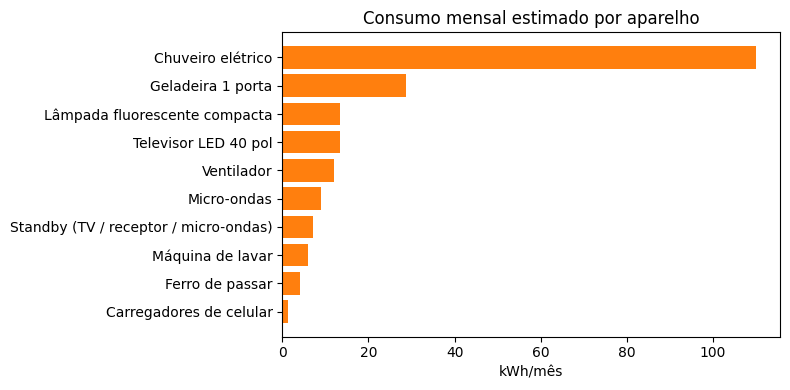

In [ ]:
ordenado = aparelhos.sort_values('consumo_kwh_mes')
plt.figure(figsize=(8, 4))
plt.barh(ordenado['aparelho'], ordenado['consumo_kwh_mes'], color='tab:orange')
plt.xlabel('kWh/mês')
plt.title('Consumo mensal estimado por aparelho')
plt.tight_layout()
plt.show()

**Observação:** o chuveiro elétrico (5,5 kW) responde por mais da metade do consumo, mesmo ficando ligado só ~40 min por dia. Isso acontece porque a **potência** dele é muito maior que a dos outros aparelhos. Por isso as alternativas focam no aquecimento de água.

## 5. Sazonalidade: regressão linear (consumo × temperatura)
Usando o que vimos na Aula 07 (regressão linear), verificamos quanto o consumo aumenta quando a temperatura cai.

- **Temperatura:** média mensal de São Paulo (INMET – Normais Climatológicas 1991–2020, valores arredondados).
- **Consumo:** histórico de 12 meses **de exemplo (fictício)**, no formato do histórico impresso na conta de luz. Deve ser trocado pelo histórico real do usuário.

In [ ]:
historico = pd.read_csv('dados/historico_exemplo.csv')
historico

,mes,temp_media_c,consumo_kwh
0,jan,22.9,188
1,fev,23.2,176
2,mar,22.5,190
3,abr,20.9,192
4,mai,18.4,218
5,jun,17.3,214
6,jul,16.6,231
7,ago,17.9,212
8,set,18.8,214
9,out,20.3,196


In [ ]:
X = historico[['temp_media_c']]
y = historico['consumo_kwh']

modeloLR = LinearRegression()
modeloLR.fit(X, y)
y_previsao = modeloLR.predict(X)

r2 = r2_score(y, y_previsao)
mae = mean_absolute_error(y, y_previsao)
mse = mean_squared_error(y, y_previsao)
print(f'Coeficiente: {modeloLR.coef_[0]:.2f} kWh por °C')
print(f'Intercepto: {modeloLR.intercept_:.1f} kWh')
print(f'R² = {r2:.3f} | MAE = {mae:.2f} kWh | MSE = {mse:.2f}')

Coeficiente: -6.89 kWh por °C
Intercepto: 339.8 kWh
R² = 0.907 | MAE = 4.78 kWh | MSE = 23.89


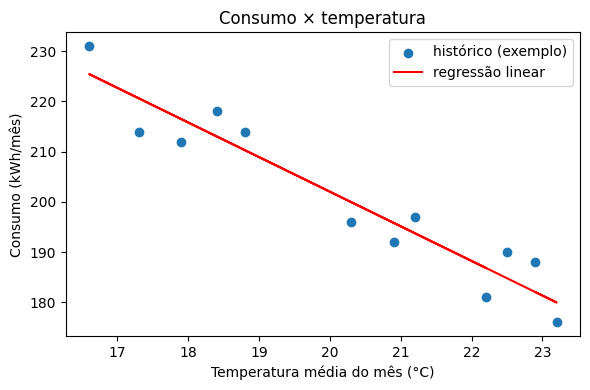

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(historico['temp_media_c'], y, label='histórico (exemplo)')
plt.plot(historico['temp_media_c'], y_previsao, color='red', label='regressão linear')
plt.xlabel('Temperatura média do mês (°C)')
plt.ylabel('Consumo (kWh/mês)')
plt.title('Consumo × temperatura')
plt.legend()
plt.tight_layout()
plt.show()

Com só 12 pontos não separamos treino e teste (ficaria com 2–3 pontos de teste); as métricas acima são **dentro da amostra** e servem só para descrever a tendência. O coeficiente é salvo para o assistente explicar ao usuário por que a conta sobe no inverno.

In [ ]:
modelo_json = {
    'coeficiente_kwh_por_c': round(float(modeloLR.coef_[0]), 3),
    'intercepto_kwh': round(float(modeloLR.intercept_), 2),
    'r2': round(float(r2), 3),
    'mae_kwh': round(float(mae), 2),
    'dados': 'historico_exemplo.csv (fictício) + INMET normais 1991-2020',
}
with open('dados/modelo_sazonalidade.json', 'w', encoding='utf-8') as arquivo:
    json.dump(modelo_json, arquivo, ensure_ascii=False, indent=2)
modelo_json

{'coeficiente_kwh_por_c': -6.89,
 'intercepto_kwh': 339.81,
 'r2': 0.907,
 'mae_kwh': 4.78,
 'dados': 'historico_exemplo.csv (fictício) + INMET normais 1991-2020'}

## 6. Comparação das alternativas
Mesma necessidade (consumo da residência-modelo) e mesmo período de referência (economia mensal, anual e saldo em 10 anos).

| Alternativa | Tipo | Ideia |
|---|---|---|
| A) Eficiência e uso consciente | economia | banho de 10 → 7 min, LED no lugar de fluorescente, cortar standby |
| B) Aquecedor solar de água | **renovável (solar térmica)** | aquece a água do banho; chuveiro fica como apoio |
| C) Energia solar fotovoltaica | **renovável (solar FV)** | gera eletricidade e compensa na conta (Lei 14.300/2022) |

Fórmulas principais:
- Geração FV (kWh/mês) = kWp × HSP × 30 × PR
- kWp necessário = (consumo − mínimo da ligação) / (HSP × 30 × PR)
- Payback simples (meses) = custo inicial / economia mensal
- CO₂ evitado (kg/ano) = kWh economizados × 12 × fator de emissão do SIN

In [ ]:
perfil = en.Perfil(pessoas=4, minutos_banho=10, potencia_chuveiro_w=5500, ligacao='bifasico', orcamento_r=3500)
alternativas = en.comparar_alternativas(perfil, premissas)
comparacao = pd.DataFrame(alternativas)
colunas = ['alternativa', 'renovavel', 'custo_inicial_r', 'economia_kwh_mes', 'economia_r_mes', 'economia_r_ano', 'payback_meses', 'saldo_10_anos_r', 'co2_evitado_kg_ano']
comparacao[colunas]

,alternativa,renovavel,custo_inicial_r,economia_kwh_mes,economia_r_mes,economia_r_ano,payback_meses,saldo_10_anos_r,co2_evitado_kg_ano
0,A) Eficiência e uso consciente,False,112.00,43.4,34.75,417.02,3.2,4058.24,20.1
1,B) Aquecedor solar de água,True,3000.00,66.0,52.80,633.60,56.8,3336.00,30.5
2,C) Energia solar fotovoltaica,True,6137.28,132.0,105.64,1267.66,58.1,6539.28,71.8


In [ ]:
print('Detalhe da alternativa A (kWh/mês):', alternativas[0]['detalhe_kwh_mes'])
fotovoltaica = alternativas[2]
print(f"FV: {fotovoltaica['potencia_kwp']} kWp, gera ~{fotovoltaica['geracao_kwh_mes']} kWh/mês, ocupa ~{fotovoltaica['area_telhado_m2']} m² de telhado")

Detalhe da alternativa A (kWh/mês): {'banho': 33.0, 'led': 5.4, 'standby': 5.0}
FV: 1.53 kWp, gera ~155.3 kWh/mês, ocupa ~7.7 m² de telhado


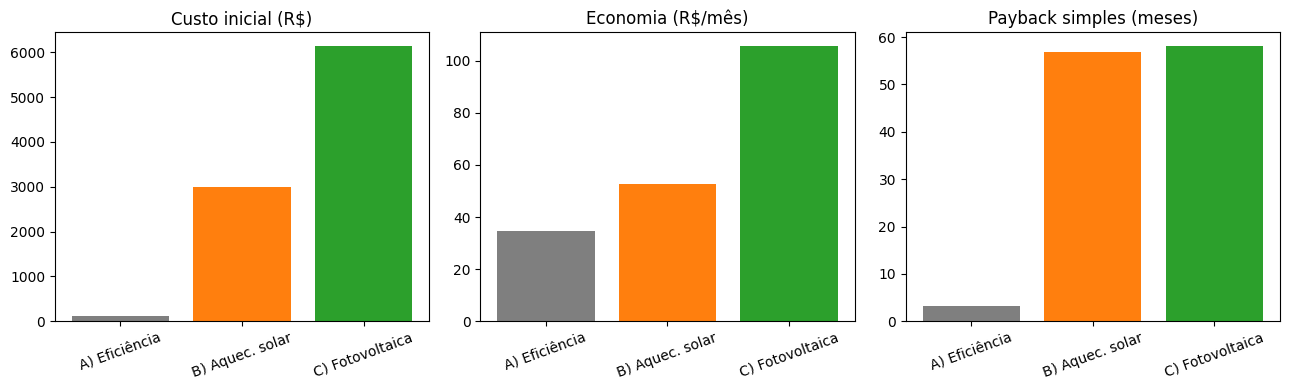

In [ ]:
nomes = ['A) Eficiência', 'B) Aquec. solar', 'C) Fotovoltaica']
cores = ['tab:gray', 'tab:orange', 'tab:green']

plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.bar(nomes, comparacao['custo_inicial_r'], color=cores)
plt.title('Custo inicial (R$)')
plt.xticks(rotation=20)

plt.subplot(1, 3, 2)
plt.bar(nomes, comparacao['economia_r_mes'], color=cores)
plt.title('Economia (R$/mês)')
plt.xticks(rotation=20)

plt.subplot(1, 3, 3)
plt.bar(nomes, comparacao['payback_meses'], color=cores)
plt.title('Payback simples (meses)')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

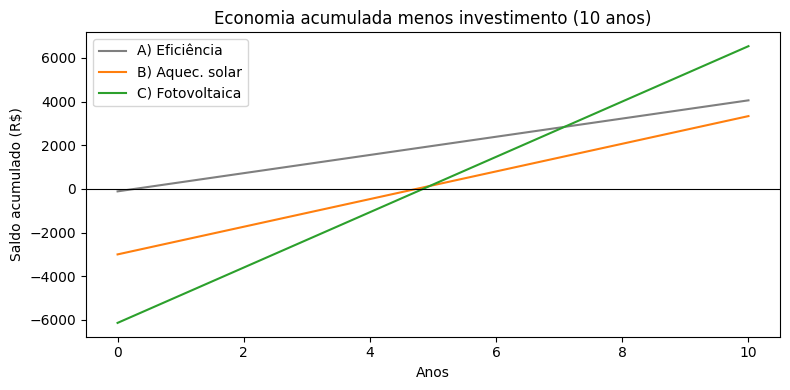

In [ ]:
meses = pd.Series(range(0, 121))

plt.figure(figsize=(8, 4))
for i in range(3):
    alternativa = alternativas[i]
    saldo = alternativa['economia_r_mes'] * meses - alternativa['custo_inicial_r']
    plt.plot(meses / 12, saldo, label=nomes[i], color=cores[i])
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('Anos')
plt.ylabel('Saldo acumulado (R$)')
plt.title('Economia acumulada menos investimento (10 anos)')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Análise de sensibilidade
Como as premissas são estimadas, testamos como o payback muda com a tarifa e com a irradiação solar.

In [ ]:
linhas = []
for tarifa in [0.60, 0.70, 0.80, 0.90, 1.00]:
    premissas_teste = premissas.copy()
    premissas_teste['tarifa_r_kwh'] = tarifa
    for alternativa in en.comparar_alternativas(perfil, premissas_teste):
        linhas.append({'tarifa_r_kwh': tarifa, 'alternativa': alternativa['alternativa'][:2], 'payback_meses': alternativa['payback_meses']})
pd.DataFrame(linhas).pivot(index='tarifa_r_kwh', columns='alternativa', values='payback_meses')

alternativa,A),B),C)
tarifa_r_kwh,,,
0.6,4.3,75.8,77.5
0.7,3.7,64.9,66.4
0.8,3.2,56.8,58.1
0.9,2.9,50.5,51.6
1.0,2.6,45.5,46.5


In [ ]:
linhas = []
for hsp in [4.0, 4.5, 5.0]:
    for custo_wp in [3.0, 4.0, 5.0]:
        premissas_teste = premissas.copy()
        premissas_teste['hsp_sao_paulo'] = hsp
        premissas_teste['custo_fv_r_por_wp'] = custo_wp
        fotovoltaica = en.alternativa_fotovoltaica(perfil, premissas_teste)
        linhas.append({'HSP': hsp, 'R$/Wp': custo_wp, 'kWp': fotovoltaica['potencia_kwp'], 'payback_anos': round(fotovoltaica['payback_meses'] / 12, 1)})
pd.DataFrame(linhas).pivot(index='HSP', columns='R$/Wp', values='payback_anos')

R$/Wp,3.0,4.0,5.0
HSP,,,
4.0,4.1,5.5,6.8
4.5,3.9,4.8,6.0
5.0,3.9,4.4,5.5


## 8. Custos, viabilidade e impactos ambientais

In [ ]:
pd.DataFrame(alternativas)[['alternativa', 'viabilidade', 'impactos_ambientais']]

,alternativa,viabilidade,impactos_ambientais
0,A) Eficiência e uso consciente,"Alta: baixo custo, serve para casa alugada, não precisa de obra.","Reduz consumo de energia e, no caso do banho, também de água. Lâmpadas antig..."
1,B) Aquecedor solar de água,"Média: exige telhado com sol (face norte), estrutura para o reservatório e i...","Fonte renovável; reduz a demanda no horário de pico (18h-21h), quando o chuv..."
2,C) Energia solar fotovoltaica,"Baixa a média para o público: exige casa própria, telhado com sol e capital ...",Fonte renovável sem emissão na operação. Fabricação dos módulos tem pegada d...


**Sobre o CO₂:** a matriz elétrica brasileira é majoritariamente renovável (fator do SIN ≈ 0,04 kg CO₂/kWh), então o CO₂ evitado por uma residência é pequeno (dezenas de kg/ano). O ganho ambiental mais relevante do aquecedor solar é **reduzir a demanda no horário de pico (18h–21h)**, quando o sistema aciona usinas térmicas.

## 9. Recomendação integrada ao assistente
A mesma função `recomendar()` usada abaixo é chamada pelo Citizen Assist AI (`assistente.py`).

In [ ]:
print('>> Casa própria, R$ 3.500 para investir')
for motivo in en.recomendar(en.Perfil(orcamento_r=3500), premissas)['motivos']:
    print(' -', motivo)
print()

print('>> Casa própria, sem dinheiro para investir')
for motivo in en.recomendar(en.Perfil(orcamento_r=0), premissas)['motivos']:
    print(' -', motivo)
print()

print('>> Casa alugada')
for motivo in en.recomendar(en.Perfil(casa_propria=False, orcamento_r=10000), premissas)['motivos']:
    print(' -', motivo)

>> Casa própria, R$ 3.500 para investir
 - 1º passo: A) Eficiência e uso consciente - custa cerca de R$ 112 e economiza ~R$ 35/mês (paga-se em ~3 meses).
 - 2º passo: B) Aquecedor solar de água - cabe no orçamento informado (R$ 3500), custa ~R$ 3000 e retorna em ~4.7 anos.
 - O chuveiro é a maior parte da sua conta, por isso o aquecedor solar costuma dar mais retorno por real investido.

>> Casa própria, sem dinheiro para investir
 - 1º passo: A) Eficiência e uso consciente - custa cerca de R$ 112 e economiza ~R$ 35/mês (paga-se em ~3 meses).
 - Para uma fonte renovável, a opção de menor custo é B) Aquecedor solar de água (~R$ 3000). Vale juntar a economia do 1º passo ou buscar programas de habitação/financiamento antes de investir.
 - O chuveiro é a maior parte da sua conta, por isso o aquecedor solar costuma dar mais retorno por real investido.

>> Casa alugada
 - 1º passo: A) Eficiência e uso consciente - custa cerca de R$ 112 e economiza ~R$ 35/mês (paga-se em ~3 meses).
 - Como a 

In [ ]:
from assistente import responder
print(responder('Por que minha conta sobe no inverno?'))

No inverno a água chega mais fria e o banho fica mais longo e mais quente, por isso o chuveiro gasta mais.
Pela regressão linear do histórico de exemplo, cada 1 °C a menos na temperatura média do mês aumenta o consumo em ~6.9 kWh (R² = 0.91).
Ex.: de janeiro (~23 °C) para julho (~17 °C) a conta sobe ~41 kWh (~R$ 33,07).
Limitação: o modelo usa dados de exemplo de 12 meses; use o histórico da sua conta para um resultado real.

Atenção: os valores são ESTIMATIVAS com base nas premissas do projeto, não são garantia de economia. Confira sempre a sua conta de luz.
Digite 'referências' para ver as fontes.


## 10. Conclusões
1. O **chuveiro elétrico** é o principal consumo da residência-modelo (~54%).
2. A **alternativa A (eficiência)** tem o menor custo e retorno em ~3 meses: é sempre o primeiro passo e serve para quem mora de aluguel.
3. Entre as renováveis, o **aquecedor solar (B)** custa cerca de metade do sistema fotovoltaico e ataca diretamente o chuveiro, com payback parecido (~5 anos). É a melhor opção para quem tem orçamento limitado e casa própria.
4. O **fotovoltaico (C)** gera a maior economia absoluta, mas exige mais capital, telhado maior e não elimina o custo mínimo da ligação.

## 11. Limitações
- Dados de consumo da residência-modelo e histórico de 12 meses são **estimados/fictícios**; o usuário deve informar sua conta real.
- Payback simples: não considera inflação, juros, reajuste de tarifa, bandeiras, degradação dos módulos nem manutenção.
- Fio B (Lei 14.300/2022) simplificado como desconto fixo de 15%; tarifa social não aplicada nos cálculos.
- Regressão com 12 pontos e uma variável: descreve tendência, não serve para previsão precisa.

## 12. Referências
Ver `README.md` (seção Referências).